# GMDCSA24

In [1]:
## estrucutura de directorios del dataset

import os
from ultralytics import YOLO
path_GMDCSA24  =  "/home/juanchx/Documents/Trabajo/Modelo_caidas/Dataset_caidas/GMDCSA24-A-Dataset-for-Human-Fall-Detection-in-Videos"
print(os.listdir(path_GMDCSA24))
os.system("tree -d 1 " + path_GMDCSA24)

['README.md', 'Subject 2', 'Subject 1', 'LICENSE', 'Subject 3', 'Subject 4', '.git']
1  [error opening dir]
/home/juanchx/Documents/Trabajo/Modelo_caidas/Dataset_caidas/GMDCSA24-A-Dataset-for-Human-Fall-Detection-in-Videos
├── Subject 1
│   ├── ADL
│   └── Fall
├── Subject 2
│   ├── ADL
│   └── Fall
├── Subject 3
│   ├── ADL
│   └── Fall
└── Subject 4
    ├── ADL
    └── Fall

12 directories


512

In [2]:
#
os.listdir(path_GMDCSA24 + "/Subject 1/Fall")

['09.mp4',
 '01.mp4',
 '03.mp4',
 '10.mp4',
 '02.mp4',
 '16.mp4',
 '13.mp4',
 '14.mp4',
 '08.mp4',
 '15.mp4',
 '07.mp4',
 '11.mp4',
 '06.mp4',
 '04.mp4',
 '05.mp4',
 '12.mp4']

In [ ]:
path_yolo8 = "/home/juanchx/.cache/kagglehub/models/bertnardomariouskono/fall-detection-yolov8/pyTorch/yolov8-nano-best-weights/1"
best = os.listdir(path_yolo8)[0]
 = YOLO(f"{path_yolo8}/{best}")

## pueba modelo video GMDCSA24
model

In [ ]:
#predecir ejemplo video
path_video = path_GMDCSA24 + "/Subject 1/Fall"
#coger video ramdom
import random
from tabnanny import verbose
# imprimir etiquetas del modelo
print(model.names)
pred_todo = []
for video in os.listdir(path_video):
    predicciones_fin = dict(zip(model.names.keys(), [0]*len(model.names)))
    dict_perdicciones  = dict(zip(model.names.keys(), [0]*len(model.names)))
    Pred = model.predict(source=path_video + '/' + video, conf=0.8, save=False, verbose=False, stream=True)
    last_class = dict(zip(model.names.keys(), [0]*len(model.names)))
    for prediction in Pred: #para cada frame del video actual
        pred_frame_actual = dict(zip(model.names.keys(), [0]*len(model.names)))
        for valor in dict_perdicciones.keys():         
            for clase in prediction.boxes.cls.tolist():
                if valor == clase :
                    pred_frame_actual[valor] = 1
        for l_class in [key for key in last_class.keys() if last_class[key] > 0]:
            if l_class in [key for key in pred_frame_actual.keys() if pred_frame_actual[key] >0]:
                dict_perdicciones[l_class] += 1
            
            if l_class in [key for key in pred_frame_actual.keys() if pred_frame_actual[key] ==0]:
                dict_perdicciones[l_class] = 0
        
        for key, value in dict_perdicciones.items():
            if value == 5:
                predicciones_fin[key] += 1
                dict_perdicciones[key] = 0

        last_class = pred_frame_actual

    zip_keys_new = [model.names[key] for key in dict_perdicciones.keys()]
    pred_todo.append((video,dict(zip(zip_keys_new, predicciones_fin.values()))))
    print((video,dict(zip(zip_keys_new, predicciones_fin.values()))))
    dict_perdicciones = dict(zip(model.names.keys(), [0]*len(model.names)))
    
      
#model.predict(source=path_video + '/'+random.choice(os.listdir(path_video)), conf=0.7, save=True)

{0: 'Fall Detected', 1: 'Walking', 2: 'Sitting'}
('09.mp4', {'Fall Detected': 25, 'Walking': 31, 'Sitting': 0})
('01.mp4', {'Fall Detected': 0, 'Walking': 0, 'Sitting': 6})
('03.mp4', {'Fall Detected': 90, 'Walking': 2, 'Sitting': 6})
('10.mp4', {'Fall Detected': 83, 'Walking': 30, 'Sitting': 0})
('02.mp4', {'Fall Detected': 11, 'Walking': 3, 'Sitting': 16})
('16.mp4', {'Fall Detected': 6, 'Walking': 0, 'Sitting': 61})
('13.mp4', {'Fall Detected': 7, 'Walking': 15, 'Sitting': 2})
('14.mp4', {'Fall Detected': 54, 'Walking': 12, 'Sitting': 9})
('08.mp4', {'Fall Detected': 81, 'Walking': 26, 'Sitting': 0})
('15.mp4', {'Fall Detected': 46, 'Walking': 0, 'Sitting': 23})
('07.mp4', {'Fall Detected': 108, 'Walking': 38, 'Sitting': 0})
('11.mp4', {'Fall Detected': 100, 'Walking': 39, 'Sitting': 2})
('06.mp4', {'Fall Detected': 38, 'Walking': 63, 'Sitting': 0})
('04.mp4', {'Fall Detected': 69, 'Walking': 60, 'Sitting': 0})
('05.mp4', {'Fall Detected': 37, 'Walking': 58, 'Sitting': 0})
('12.mp4'

In [ ]:
# 4.CCTV Incident Dataset -Fall & Lying Down Detection

import kagglehub

# Download latest version
path = kagglehub.dataset_download("simuletic/cctv-incident-dataset-fall-and-lying-down-detection")

print("Path to dataset files:", path)

Path to dataset files: /home/juanchx/.cache/kagglehub/datasets/simuletic/cctv-incident-dataset-fall-and-lying-down-detection/versions/1


['example_image.png', 'images', 'labels', 'dataset.yaml']


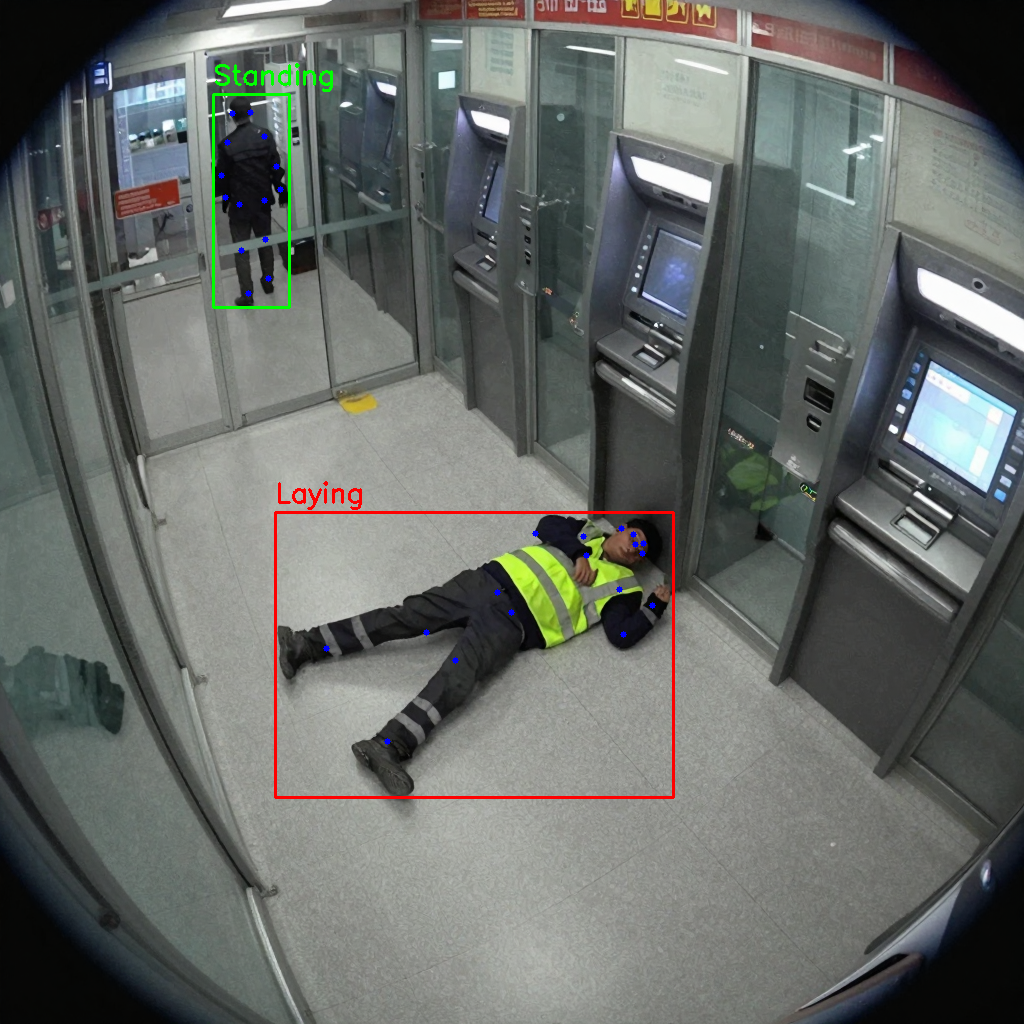

In [10]:
# revisar datasets
# obtener datos de path = kagglehub.dataset_download("simuletic/cctv-incident-dataset-fall-and-lying-down-detection")
import os
print(os.listdir("/home/juanchx/.cache/kagglehub/datasets/simuletic/cctv-incident-dataset-fall-and-lying-down-detection/versions/1/laying_dataset"))
path =           "/home/juanchx/.cache/kagglehub/datasets/simuletic/cctv-incident-dataset-fall-and-lying-down-detection/versions/1/laying_dataset"
from IPython.display import Image
Image(f"{path}/example_image.png", width=600)

In [4]:
###

import kagglehub

# Download latest version
path = kagglehub.dataset_download("tuyenldvn/falldataset-imvia")

print("Path to dataset files:", path)

Path to dataset files: /home/juanchx/.cache/kagglehub/datasets/tuyenldvn/falldataset-imvia/versions/2


In [5]:
from procesado import Procesado
import cv2

procesar = Procesado()
fuente = "/home/juanchx/Documents/Trabajo/Modelo_caidas/Edinburgh office monitoring video dataset/day_1.avi"
salida = "/home/juanchx/Documents/Trabajo/Modelo_caidas/Edinburgh office monitoring video dataset/day_1_15fps.mp4"
video_final =procesar.reducir_fps_video(fuente=fuente, fps_destino=15, salida=salida)
#guardar video mp4



ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab